<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/_banners/opim5512_banner.svg" alt="OPIM 5512 banner" width="100%">

# Lab 6C · Two Kinds of Uncertainty, One Range, Live
### Your model's mistakes + the weather's mistakes → low, expected and high every hour

*Lab 6, notebook 3 of 3 · Colab · your energy project on Google Cloud*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/Lab6C_Combine_and_Ship.ipynb)

Where you are:
- **6A:** the weather forecast is wrong too, and **8 HRRR runs** forecast every hour of tomorrow, a little differently.
- **6B:** a **quantile forest** gives an honest 80% range, but only for the **model's** mistakes. Fed a real forecast,
  its range got too narrow.

Tonight you combine the two and ship it:

| Part | Time | What you do |
|---|---|---|
| **0. Sync your fork** | 5 min | Get the new `forecast-24h` that knows how to use the HRRR runs |
| **1. Setup** | 3 min | Data, the HRRR archive, and 6B's quantile forest |
| **2. The 8 runs, as issued** | 5 min | Rebuild the lagged HRRR ensemble for every hour of 2026 |
| **3. Three ranges** | 10 min | Model only, weather only, and both pooled, scored by CRPS |
| **4. How many runs?** | 5 min | 1, 2, 4 or 8 runs in the pool |
| **5. Ship it** | 10 min | Upload the quantile forest, run `forecast-24h`, check the range is live |
| **6. Tomorrow** | 5 min | Your next 24 hours as a band |
| **7. Submit Lab 6** | 5 min | Your "Range is live" line and the 12 answers |

# Part 0 · Sync your fork (5 min)
Dr. Dave updated `forecast-24h` in the class repo. Bring the update into **your** fork:

1. Open your fork on GitHub (`github.com/YOUR-USERNAME/energy-forecasting`).
2. Click **Sync fork**, then **Update branch**.
3. Click **Actions**: **Deploy forecast-24h** starts by itself. Wait for the green check (about 3 minutes).

What's new: a `range_method` called **`hrrr_qrf_pooled`**. Every hour at :05, Dr. Dave's class job saves the 8 newest
HRRR runs at Bradley to one public file
([bdl_hrrr_runs.csv](https://storage.googleapis.com/opim5512-leaderboard-f26/weather/bdl_hrrr_runs.csv)). At :20 your
`forecast-24h` reads that file, runs your quantile forest on **every run**, pools the answers, and writes low, expected
and high. One class job instead of 30, so nobody's function downloads a weather model. (If the file is ever missing,
your function falls back to the NWS forecast and says so: `hrrr_qrf_pooled_nws`.)

# Part 1 · Setup (3 min)

In [1]:
!pip install -q scikit-learn==1.6.1 quantile-forest==1.4.2

import io
import json
import os
import time
import warnings
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from pandas.tseries.holiday import USFederalHolidayCalendar
from quantile_forest import RandomForestQuantileRegressor

warnings.filterwarnings("ignore")
print("scikit-learn", sklearn.__version__, "(production uses 1.6.1)")
SEED = 42
LOCAL = "America/New_York"
DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
df = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
archive = pd.read_csv(DATA + "bdl_hrrr_asissued_2023_2026.csv.gz", parse_dates=["init_utc", "hour_utc"])
print(len(df), "hours of weather and load |", archive["init_utc"].nunique(), "HRRR runs in the archive")

scikit-learn 1.6.1 (production uses 1.6.1)


33215 hours of weather and load | 5591 HRRR runs in the archive


Your settings (the same as Lab 5). Leave them alone for **demo mode**: everything runs except the upload in Part 5.

In [2]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"     # e.g. "energy-dww05002-f26"
BUCKET_NAME = "YOUR-ENERGY-PROJECT-ID"    # usually the same as your project ID
NETID = "abc12345"                        # your UConn NetID, lower case

In [3]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
CALENDAR = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
FEATURES = CALENDAR + WEATHER + ["load_yesterday_mw"]


def make_features(hours_utc, weather, load):
    """One row of model inputs per hour (word for word from Lab 5)."""
    hours_utc = pd.DatetimeIndex(hours_utc)
    local = hours_utc.tz_convert("America/New_York")
    out = pd.DataFrame(index=hours_utc)
    out["hour"] = local.hour
    out["day_of_week"] = local.dayofweek
    out["month"] = local.month
    out["is_weekend"] = (local.dayofweek >= 5).astype(int)
    holidays = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")
    out["is_holiday"] = local.tz_localize(None).normalize().isin(holidays).astype(int)
    for column in WEATHER:
        out[column] = weather[column].reindex(hours_utc).values
    yesterday = load.reindex(hours_utc - pd.Timedelta(hours=24)).values
    hour_before = load.reindex(hours_utc - pd.Timedelta(hours=25)).values
    out["load_yesterday_mw"] = np.where(np.isnan(yesterday), hour_before, yesterday)
    return out[FEATURES]


def crps(actual, low, expected, high):
    """The leaderboard's CRPS for each hour (MW, lower is better), from 6B."""
    actual = np.asarray(actual, dtype=float)
    low = np.asarray(low, dtype=float)
    high = np.asarray(high, dtype=float)
    outside = np.clip(low - actual, 0, None) + np.clip(actual - high, 0, None)
    return (0.5 * np.abs(actual - np.asarray(expected, dtype=float)) + 0.1 * (high - low) + 1 * outside) / 1.5


def judge(method, low, expected, high, actual):
    """Average CRPS, coverage and width over the hours given (from 6B)."""
    actual = np.asarray(actual, dtype=float)
    inside = (actual >= np.asarray(low)) & (actual <= np.asarray(high))
    return {"method": method,
            "inside range (%)": round(100 * float(np.mean(inside)), 1),
            "average width (MW)": round(float(np.mean(np.asarray(high) - np.asarray(low)))),
            "CRPS (MW)": round(float(np.mean(crps(actual, low, expected, high))), 1)}


X_all = make_features(df.index, df, df["load_mw"]).iloc[25:]
y_all = df["load_mw"].loc[X_all.index]
years = X_all.index.tz_convert(LOCAL).year
TEST_YEAR = 2026
X_train = X_all[years < TEST_YEAR]
y_train = y_all[years < TEST_YEAR]

started = time.time()
qrf = RandomForestQuantileRegressor(n_estimators=100, min_samples_leaf=10, random_state=SEED, n_jobs=-1)
qrf.fit(X_train, y_train)
print("6B's quantile forest, trained on 2023-2025, in", round(time.time() - started), "seconds")

6B's quantile forest, trained on 2023-2025, in 12 seconds


# Part 2 · The 8 runs, as issued (5 min)
In 6A Part 8 you saw tonight's 8 runs. Now rebuild them for **every hour of 2026**, honestly: for a forecast made
`hours_ahead` hours before the target hour, run 0 is the newest run that was **ready** then, run 1 the one 6 hours older,
and so on up to run 7 (about two days older). A run only covers 48 hours, so the oldest runs often don't reach the
target: those cells stay empty, exactly like in production.

In [4]:
READY_HOURS = 2                           # a run is published about 1 h 45 min after it starts
N_RUNS = 8


def hrrr_runs_as_issued(target_hours, hours_ahead, n_runs=N_RUNS):
    """A list of n_runs weather tables (newest run first) for the target hours, as you'd have had them
    hours_ahead hours earlier. Hours a run doesn't cover are NaN."""
    issued = target_hours - pd.Timedelta(hours=hours_ahead)
    newest = (issued - pd.Timedelta(hours=READY_HOURS)).floor("6h")
    tables = []
    for k in range(n_runs):
        wanted = pd.DataFrame({"init_utc": newest - pd.Timedelta(hours=6 * k), "hour_utc": target_hours})
        found = wanted.merge(archive, on=["init_utc", "hour_utc"], how="left")
        tables.append(pd.DataFrame(found[WEATHER].values, index=target_hours, columns=WEATHER))
    return tables


test_hours = X_all.index[(years == TEST_YEAR) & (X_all.index <= archive["hour_utc"].max())]
y_test = y_all.loc[test_hours]
runs_12 = hrrr_runs_as_issued(test_hours, 12)
covered = pd.DataFrame(index=test_hours)
for k in range(N_RUNS):
    covered["run " + str(k)] = runs_12[k]["temp_f"].notna()
print(len(test_hours), "test hours. Made 12 hours ahead, each hour is covered by", int(covered.sum(axis=1).min()), "to",
      int(covered.sum(axis=1).max()), "runs (average", round(float(covered.sum(axis=1).mean()), 1), ")")

example = test_hours[len(test_hours) // 2]
temps = []
for k in range(N_RUNS):
    temps.append(float(runs_12[k].loc[example, "temp_f"]))
print("Example,", example.tz_convert(LOCAL).strftime("%b %d %I %p"), "| the 8 runs said (°F, newest first):", temps,
      "| actual:", df.loc[example, "temp_f"])

6911 test hours. Made 12 hours ahead, each hour is covered by 5 to 6 runs (average 5.8 )
Example, May 25 12 AM | the 8 runs said (°F, newest first): [52.4, 52.0, 51.2, 49.8, 50.2, 51.8, nan, nan] | actual: 53.0


# Part 3 · Three ranges (10 min)
Three ways to make low, expected and high from the same quantile forest and the same runs:

| Method | How | Uncertainty it knows about |
|---|---|---|
| **A. Model only** (6B) | the quantile forest's 10th, 50th and 90th percentile, fed the **newest** run | the model's |
| **B. Weather only** | the forest's **expected** value for each of the 8 runs; low and high = the 10th and 90th percentile of those 8 | the weather's |
| **C. Both, pooled** | the forest's 20 percentiles (2.5%, 7.5%, ..., 97.5%, each standing for 5% of the chances) for **each** run, all thrown into one pile per hour; low, expected and high = the 10th, 50th and 90th percentile of the pile | both |

**Why C works:** each run gives a full range of loads *if that run's weather is right*. We don't know which run is
right, so we keep every run's range in the pile. When the runs agree, the pile looks like one range. When they
disagree (a front's timing, a surprise heat wave), the pile spreads out, and so does your range. Statisticians call
this a **mixture**.

`pooled` below is the exact same math your `forecast-24h` now runs every hour.

In [5]:
POOL_QUANTILES = list(np.round(np.arange(0.025, 0.976, 0.05), 3))     # 0.025, 0.075, ..., 0.975: 20 percentiles, 5% of the chances each


def forest_on_runs(runs):
    """The forest's 20 percentiles for every hour and every run: an array of hours x runs x 20 (NaN = not covered)."""
    out = np.full((len(test_hours), len(runs), len(POOL_QUANTILES)), np.nan)
    for k in range(len(runs)):
        X = make_features(test_hours, runs[k], df["load_mw"])
        ok = X[WEATHER].notna().all(axis=1).values
        if ok.any():
            out[ok, k, :] = qrf.predict(X[ok], quantiles=POOL_QUANTILES)
    return out


def pooled(q, n_runs=N_RUNS):
    """Method C: pool the 20 percentiles of the newest n_runs runs, then read off the 10th, 50th and 90th.
    method="hazen" treats each value as the middle of its 5% slice, so one run alone gives back exactly its own range."""
    pile = q[:, :n_runs, :].reshape(len(q), -1)
    return np.nanpercentile(pile, [10, 50, 90], axis=1, method="hazen")



started = time.time()
three = []
q_by_lead = {}
for ahead in [1, 12, 24]:
    q = forest_on_runs(hrrr_runs_as_issued(test_hours, ahead))
    q_by_lead[ahead] = q
    ok = ~np.isnan(q[:, 0, 0])                         # hours where the newest run exists
    lead = str(ahead) + " h ahead"
    a = pooled(q[ok], 1)                              # the newest run alone = the forest's own 10th, 50th, 90th
    three.append({"lead": lead} | judge("A. model only", a[0], a[1], a[2], y_test[ok]))
    middles = np.nanmedian(q[ok], axis=2)             # each run's middle value (its expected load)
    b = np.nanpercentile(middles, [10, 50, 90], axis=1)
    three.append({"lead": lead} | judge("B. weather only", b[0], b[1], b[2], y_test[ok]))
    c = pooled(q[ok])
    three.append({"lead": lead} | judge("C. both, pooled", c[0], c[1], c[2], y_test[ok]))
print("done in", round(time.time() - started), "seconds")
three = pd.DataFrame(three)
three.pivot(index="method", columns="lead", values=["inside range (%)", "CRPS (MW)"])

done in 12 seconds


inside range (%)                       CRPS (MW)             \
lead                   1 h ahead 12 h ahead 24 h ahead 1 h ahead 12 h ahead   
method                                                                        
A. model only               76.0       74.5       73.5     108.4      113.1   
B. weather only             17.9       15.8       12.9     149.3      152.8   
C. both, pooled             76.7       76.0       75.2     109.4      111.1   

                            
lead            24 h ahead  
method                      
A. model only        115.8  
B. weather only      157.8  
C. both, pooled      112.7

**Read it, one lead at a time:**
- **A (model only)** is overconfident with real forecasts (6B Part 5): well under 80% inside, and worse the further
  ahead.
- **B (weather only)** is far too narrow: runs that mostly agree with each other say nothing about the **model's** own
  misses, which are much bigger.
- **C (pooled)** has the best coverage and the **lowest CRPS 12 and 24 hours ahead**, where the weather is most
  uncertain. One hour ahead it's a tie or a hair worse: the newest run is so fresh that two-day-old runs only blur it.
  The range breathes: narrow when the runs agree, wide when they don't.
- Even C lands a few points under 80% inside. If your live coverage on the leaderboard says the same, widen it a little
  with `"range_widen"` in the model card (Part 7).

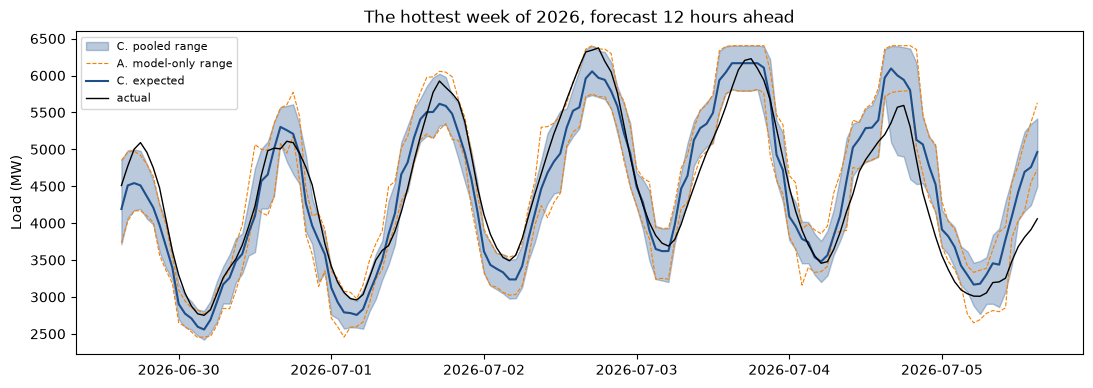

In [6]:
q = q_by_lead[12]
c = pooled(q)
a = pooled(q, 1)
band = pd.DataFrame({"low": c[0], "expected": c[1], "high": c[2],
                     "A low": a[0], "A high": a[2], "actual": y_test.values}, index=test_hours)
hottest = df.loc[test_hours, "temp_f"].idxmax()
week = band.loc[hottest - pd.Timedelta(days=3):hottest + pd.Timedelta(days=3)]
hours_local = week.index.tz_convert(LOCAL).tz_localize(None)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.fill_between(hours_local, week["low"], week["high"], alpha=0.3, color="#1d4e89", label="C. pooled range")
ax.plot(hours_local, week["A low"], color="#f77f00", linewidth=0.8, linestyle="--", label="A. model-only range")
ax.plot(hours_local, week["A high"], color="#f77f00", linewidth=0.8, linestyle="--")
ax.plot(hours_local, week["expected"], color="#1d4e89", label="C. expected")
ax.plot(hours_local, week["actual"], color="black", linewidth=1, label="actual")
ax.set_ylabel("Load (MW)")
ax.set_title("The hottest week of " + str(TEST_YEAR) + ", forecast 12 hours ahead")
ax.legend(fontsize=8, loc="upper left")
plt.show()

# Part 4 · How many runs? (5 min)
More runs = more weather scenarios in the pile, but the oldest runs are two days old and worse. Score the pool with the
newest 1, 2, 4 and 8 runs (12 hours ahead).

In [7]:
sweep = []
q = q_by_lead[12]
ok = ~np.isnan(q[:, 0, 0])
for n in [1, 2, 4, 8]:
    c = pooled(q[ok], n)
    sweep.append({"runs in the pool": n} | judge("pooled", c[0], c[1], c[2], y_test[ok]))
sweep = pd.DataFrame(sweep).drop(columns="method").set_index("runs in the pool")
best_runs = int(sweep["CRPS (MW)"].idxmin())
print("Lowest CRPS with", best_runs, "runs")
sweep

Lowest CRPS with 8 runs


,inside range (%),average width (MW),CRPS (MW)
runs in the pool,,,
1,74.5,466,113.1
2,75.5,472,111.7
4,75.8,477,111.2
8,76.0,481,111.1


Pick the number you'll ship. `HRRR_RUNS = best_runs` uses the winner; type a number to overrule it. It goes in your
model card as `"hrrr_runs"`.

In [8]:
HRRR_RUNS = best_runs
print("Shipping with the newest", HRRR_RUNS, "HRRR runs")

Shipping with the newest 8 HRRR runs


# Part 5 · Ship it (10 min)

## 5a. The final quantile forest and the model card
Like Lab 5, the shipped model is refit on **all** the data (2023 to October 15, 2026). The model card tells
`forecast-24h` what to do with it. Your Lab 5 `model.joblib` stays in the bucket as the backup.

In [9]:
started = time.time()
final_qrf = RandomForestQuantileRegressor(n_estimators=100, min_samples_leaf=10, random_state=SEED, n_jobs=-1)
final_qrf.fit(X_all, y_all)
joblib.dump(final_qrf, "model_qrf.joblib", compress=3)
size_mb = round(os.path.getsize("model_qrf.joblib") / 1e6, 1)
print("Refit on", len(X_all), "hours in", round(time.time() - started), "seconds:", size_mb, "MB")

row = three[(three["lead"] == "12 h ahead") & (three["method"] == "C. both, pooled")].iloc[0]
card = {
    "model_type": "RandomForestQuantileRegressor",
    "best_params": {"n_estimators": "100", "min_samples_leaf": "10"},
    "trained_at": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "sklearn_version": sklearn.__version__,
    "features": FEATURES,
    "range_method": "hrrr_qrf_pooled",
    "range_quantiles": [0.1, 0.9],
    "hrrr_runs": HRRR_RUNS,
    "range_widen": 1.0,
    "test_inside_pct_12h": float(row["inside range (%)"]),
    "test_width_mw_12h": float(row["average width (MW)"]),
    "test_crps_mw_12h": float(row["CRPS (MW)"]),
    "train_period": "2023-01-01 to 2026-10-15 (Connecticut time)",
    "seed": SEED,
}
with open("model_card.json", "w") as f:
    json.dump(card, f, indent=2)
card

Refit on 33190 hours in 9 seconds: 8.6 MB


{'model_type': 'RandomForestQuantileRegressor',
 'best_params': {'n_estimators': '100', 'min_samples_leaf': '10'},
 'trained_at': '2026-10-29T19:17:33Z',
 'sklearn_version': '1.6.1',
 'features': ['hour',
  'day_of_week',
  'month',
  'is_weekend',
  'is_holiday',
  'temp_f',
  'dewpoint_f',
  'rel_humidity_pct',
  'wind_speed_mph',
  'cloud_cover_pct',
  'load_yesterday_mw'],
 'range_method': 'hrrr_qrf_pooled',
 'range_quantiles': [0.1, 0.9],
 'hrrr_runs': 8,
 'range_widen': 1.0,
 'test_inside_pct_12h': 76.0,
 'test_width_mw_12h': 481.0,
 'test_crps_mw_12h': 111.1,
 'train_period': '2023-01-01 to 2026-10-15 (Connecticut time)',
 'seed': 42}

## 5b. Sign in, check, upload, run `forecast-24h` now
The same checks as Lab 5 Part 7b. When the **"Allow access"** pop-up opens, pick the Gmail you used for Google Cloud.
Then it uploads `model_qrf.joblib` and the new card (copies of both go to `energy/models/history/`), starts
`forecast-24h`, and waits up to 4 minutes for your forecast.

In [10]:
UPLOAD = "YOUR-ENERGY-PROJECT-ID" not in PROJECT_ID and "YOUR-ENERGY-PROJECT-ID" not in BUCKET_NAME
latest_blob = None
if not UPLOAD:
    print("DEMO MODE: type your PROJECT_ID and BUCKET_NAME in Part 1 to ship. Nothing uploaded.")
else:
    from zoneinfo import ZoneInfo

    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()
    account_lines = !gcloud config get-value account
    print("1. Signed in as:", account_lines[-1].strip() if len(account_lines) > 0 else "unknown")
    bucket = storage.Client(project=PROJECT_ID).bucket(BUCKET_NAME)
    if not bucket.exists():
        raise RuntimeError("Can't see the bucket " + BUCKET_NAME + ": check Part 1, or Runtime > Disconnect and delete "
                           "runtime and pick your Google Cloud Gmail in the pop-up.")
    print("2. Bucket found:", BUCKET_NAME)
    state_lines = !gcloud functions describe forecast-24h --gen2 --region=us-central1 --project={PROJECT_ID} --format="value(state)"
    print("3. forecast-24h:", state_lines[-1].strip() if len(state_lines) > 0 else "NOT FOUND")

    stamp = card["trained_at"].replace(":", "-")
    for name in ["model_qrf.joblib", "model_card.json"]:
        bucket.blob("energy/models/" + name).upload_from_filename(name)
        bucket.blob("energy/models/history/" + name.replace(".", "_" + stamp + ".", 1)).upload_from_filename(name)
        print("Live:", "gs://" + BUCKET_NAME + "/energy/models/" + name)

    started = datetime.now(timezone.utc)
    !gcloud scheduler jobs run forecast-24h-hourly --location=us-central1 --project={PROJECT_ID}
    print("Started forecast-24h. Waiting for your forecast", end="")
    latest_blob = bucket.blob("energy/forecasts/latest.csv")
    ready = False
    for attempt in range(16):                 # every 15 seconds, for up to 4 minutes
        time.sleep(15)
        print(".", end="")
        if latest_blob.exists():
            latest_blob.reload()
            if latest_blob.updated > started:
                ready = True
                break
    print()
    if not ready:
        print("No new forecast after 4 minutes. Run the log cell below and paste the log into Claude.")
    else:
        mine = pd.read_csv(io.BytesIO(latest_blob.download_as_bytes()))
        method = str(mine["range_method"].iloc[0])
        width = round(float((mine["predicted_high_mw"] - mine["predicted_low_mw"]).mean()))
        if method == "hrrr_qrf_pooled":
            print("Range is live:", NETID.strip().lower(), "| hrrr_qrf_pooled |", HRRR_RUNS, "runs | average width", width, "MW")
        elif method == "hrrr_qrf_pooled_nws":
            print("Range is live (NWS backup, the class HRRR file was unavailable):", NETID.strip().lower(), "| width", width, "MW")
        elif method in ["none", "nan"]:
            print("Your forecast-24h doesn't know hrrr_qrf_pooled yet: do Part 0 (Sync fork), wait for the green deploy, re-run this cell.")
        else:
            print("range_method came back as", method, "- run the log cell below and look for range_error.")

DEMO MODE: type your PROJECT_ID and BUCKET_NAME in Part 1 to ship. Nothing uploaded.


**Optional, only for troubleshooting.** The newest log lines of `forecast-24h`. Look for `"range_method"`,
`"weather_source"`, `"runs_per_hour_min"` and `"range_error"`.

In [11]:
if UPLOAD:
    !gcloud functions logs read forecast-24h --region=us-central1 --gen2 --limit=10 --project={PROJECT_ID}
else:
    print("Demo mode: no log to read.")

Demo mode: no log to read.


# Part 6 · Tomorrow (5 min)
Your next 24 hours as a band, with the last two days of actual load and ISO New England's own forecast. Demo mode
shows the last day of the 2026 backtest instead.

DEMO: the last day of the backtest, 12 hours ahead, pooled


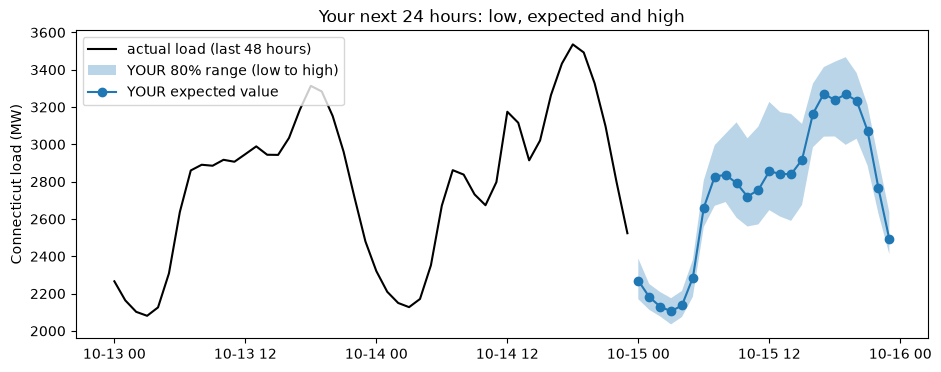

Peak: 3272 MW on Thu 05 PM | 80% range 3041 to 3414 MW


In [12]:
def read_bucket_csv(key):
    blob = bucket.blob(key)
    if not blob.exists():
        return None
    return pd.read_csv(io.BytesIO(blob.download_as_bytes()))


isone = None
if UPLOAD and latest_blob is not None and latest_blob.exists():
    mine = read_bucket_csv("energy/forecasts/latest.csv")
    mine["target_hour_utc"] = pd.to_datetime(mine["target_hour_utc"], utc=True)
    mine = mine.set_index("target_hour_utc")
    forecast = mine["predicted_load_mw"]
    band_low = mine["predicted_low_mw"]
    band_high = mine["predicted_high_mw"]
    actual_table = read_bucket_csv("energy/datasets/ct_load_5min_hourly_master.csv")
    actual_table["hour_utc"] = pd.to_datetime(actual_table["hour_utc"], utc=True)
    actual = actual_table.set_index("hour_utc")["load_mw_5min_avg"].sort_index().tail(48)
    isone_table = read_bucket_csv("energy/datasets/isone_ct_forecast_master.csv")
    if isone_table is not None:
        isone_table["target_hour_utc"] = pd.to_datetime(isone_table["target_hour_utc"], utc=True)
        isone_table = isone_table.sort_values(["target_hour_utc", "issued_at_utc"])
        isone = isone_table.drop_duplicates("target_hour_utc", keep="last").set_index("target_hour_utc")["isone_forecast_mw"]
        isone = isone.reindex(forecast.index)
    print("LIVE: your forecast, issued", mine["issued_at_utc"].iloc[0], "(UTC)")
else:
    last_day = band.index[-24:]
    forecast = band.loc[last_day, "expected"]
    band_low = band.loc[last_day, "low"]
    band_high = band.loc[last_day, "high"]
    actual = band["actual"].iloc[-72:-24]
    print("DEMO: the last day of the backtest, 12 hours ahead, pooled")

hours_local = forecast.index.tz_convert(LOCAL).tz_localize(None)
plt.figure(figsize=(11, 4))
plt.plot(actual.index.tz_convert(LOCAL).tz_localize(None), actual.values, color="black", label="actual load (last 48 hours)")
plt.fill_between(hours_local, band_low.values, band_high.values, alpha=0.3, label="YOUR 80% range (low to high)")
plt.plot(hours_local, forecast.values, marker="o", label="YOUR expected value")
if isone is not None and isone.notna().any():
    plt.plot(hours_local, isone.values, linestyle="--", label="ISO New England's forecast")
plt.ylabel("Connecticut load (MW)")
plt.title("Your next 24 hours: low, expected and high")
plt.legend(loc="upper left")
plt.show()
peak = forecast.idxmax()
print("Peak:", round(forecast.max()), "MW on", peak.tz_convert(LOCAL).strftime("%a %I %p"),
      "| 80% range", round(band_low[peak]), "to", round(band_high[peak]), "MW")

# Part 7 · Submit Lab 6 (5 min)

## The Lab 6 leaderboard
The class leaderboard ranks Lab 6 ranges by **CRPS** (lower is better) and shows how often the actual landed inside
your range (aim: about 80%): https://storage.googleapis.com/opim5512-leaderboard-f26/index.html

Your first scored hour shows up after the collector's next run (:35). Check it over the next few days. If coverage stays
well under 80%, widen your range without retraining: set `"range_widen": 1.2` in `model_card.json` and upload only the
card. `forecast-24h` uses it at its next run.

## The answers for 6C
9. **Part 2:** Made 12 hours ahead, how many HRRR runs covered each hour on average? Why not always 8?
10. **Part 3:** Which method had the lowest CRPS at 24 hours ahead, and how close was its coverage to 80%? Why is
    "weather only" so overconfident?
11. **Part 4:** How many runs did you ship, and why might the oldest runs hurt?
12. **Part 6:** What's your range at tomorrow's peak hour? Is ISO New England's forecast inside it?

## Submit Lab 6
In the **Submit Lab 6** text box on HuskyCT, paste:
1. the **"Range is live"** line Part 5b printed, then
2. your answers to questions **1 to 12** (1 to 4 from 6A, 5 to 8 from 6B, 9 to 12 above), numbered.

Due **Friday, November 20, 11:59 PM** (Hartford and Stamford).

---

**Data credits:** weather from NOAA's HRRR and RTMA via dynamical.org, the Iowa State Mesonet and the National Weather
Service; load and forecasts from ISO New England. hefty by Will Hobbs (github.com/williamhobbs/hefty).